# School zones and places

Georgia Civic Data publishes school attendance zones: the areas that assign
a home to its zoned elementary, middle and high school. This article maps
one district's zones, checks which schools have no zone and how precise the
zones are, and finds the places a location falls in.

The geometry functions return geopandas `GeoDataFrame`s, so install the
`geo` extra (`pip install georgiacivicdata[geo]`) to map them. For plain
tables, use `geometry=False`.

In [1]:
import warnings

import pandas as pd

warnings.formatwarning = lambda message, category, *args, **kwargs: (
    f"{category.__name__}: {message}\n"
)
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", 60)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

import georgiacivicdata as gcd

## Map one district's zones

In [3]:
zones = gcd.school_zones(district="Atlanta Public Schools")
zones.groupby(["zone_level", "method", "accuracy_class"]).size()

zone_level  method        accuracy_class      
elementary  official_gis  authoritative_vector    45
high        official_gis  authoritative_vector     9
middle      official_gis  authoritative_vector    13
dtype: int64

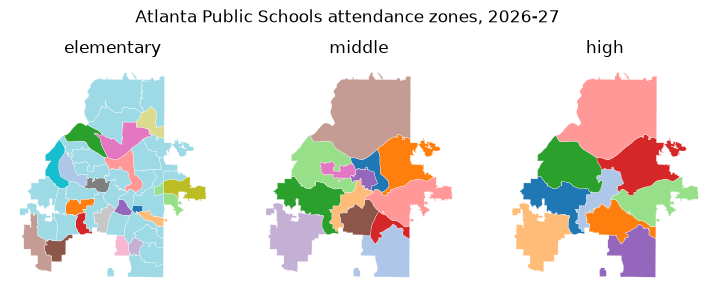

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3.4))
for ax, level in zip(axes, ["elementary", "middle", "high"]):
    zones[zones["zone_level"] == level].plot(
        ax=ax, column="school_name", cmap="tab20", edgecolor="white", linewidth=0.2
    )
    ax.set_title(level)
    ax.set_axis_off()
fig.suptitle("Atlanta Public Schools attendance zones, 2026-27")
plt.show()

Each colour is a school. The default `resolution="display"` returns
simplified polygons for maps. `resolution="full"` returns the source
polygons, which are much larger; filter to a district before asking for
them.

## Schools without a zone

Charter, magnet, alternative and virtual schools have no attendance zone.
`gcd.school_zone_status()` says which schools have one and why the others
don't:

In [5]:
status = gcd.school_zone_status(district="Atlanta Public Schools")
status["zone_status"].value_counts()

zone_status
zoned      64
no_zone    23
Name: count, dtype: int64[pyarrow]

The schools with no zone, by reason:

In [6]:
status.loc[status["zone_status"] == "no_zone", "no_zone_category"].value_counts().head()

no_zone_category
charter                     16
magnet_or_choice             3
closed_or_consolidated       2
residential_or_treatment     1
alternative                  1
Name: count, dtype: int64[pyarrow]

In [7]:
print(gcd.meta(status)["note"])

Whether each school has an attendance zone on this platform and, if not, why. zoned says only that a zone is published here, not that it covers every grade the school teaches. Not an official enrollment determination: confirm with the school district.


## How precise are the zones?

Zones come from very different sources. Some are the district's official GIS
layers; others are digitized from PDF maps, rebuilt from street lists, or
are the whole district outline (in districts with one school per grade).
Every zone says how it was built (`method`) and how exact it is
(`accuracy_class`); treat them accordingly.

In [8]:
coverage = gcd.school_zone_coverage()
pd.crosstab(coverage["level_status"], coverage["zone_level"])

zone_level,elementary,high,middle
level_status,,,
not_available,29,5,10
one_school_per_grade,82,130,115
partial,10,6,9
served_by_other_district,0,1,0
zoned,59,38,46


`gcd.school_zone_coverage()` gives one row per district and level, with the
share of the district's land and 2020 population its zones cover, and the
reason for anything short of complete:

In [9]:
coverage.loc[
    coverage["district_name"] == "Appling County",
    ["zone_level", "level_status", "pct_population", "methods", "reason"],
]

,zone_level,level_status,pct_population,methods,reason
0,elementary,not_available,NaN,district_outline,Elementary: The district has separate elementary attenda...
1,middle,one_school_per_grade,1.0,district_outline,Elementary: The district has separate elementary attenda...
2,high,one_school_per_grade,1.0,district_outline,Elementary: The district has separate elementary attenda...


## Locate a place

`gcd.locate()` takes points (`lat`, `lon`) or street addresses and returns
the county, Census tract and block group, school district and zoned schools
each falls in, one row per place.

In [10]:
landmarks = pd.DataFrame(
    {
        "landmark": [
            "Georgia State Capitol",
            "Stone Mountain Park",
            "Okefenokee Swamp Park",
            "Appling County Courthouse",
        ],
        "lat": [33.7490, 33.8053, 31.0558, 31.7782],
        "lon": [-84.3880, -84.1455, -82.2701, -82.3482],
    }
)
places = gcd.locate(lat=landmarks["lat"], lon=landmarks["lon"], id=landmarks["landmark"])
places[["id", "geographic_type", "geographic_id", "geographic_name", "grades"]].head()

GCDAdvisory: A zone is the default assignment, not the only option: a Georgia student may attend another public school by transfer, or a charter, magnet or other choice school. See attendance_rules for the main ways.


,id,geographic_type,geographic_id,geographic_name,grades
0,Georgia State Capitol,county,13121,Fulton,<NA>
1,Georgia State Capitol,tract,13121003500,Census Tract 35,<NA>
2,Georgia State Capitol,block_group,131210035001,"Block Group 1, Census Tract 35, Fulton County",<NA>
3,Georgia State Capitol,school_district,761,Atlanta Public Schools,<NA>
4,Georgia State Capitol,elementary_school,761-0199,Centennial Academy (Charter),K-5


The output is long (`head()` shows its first five rows): filter it to the
rows you need, such as `places[places["geographic_type"] == "high_school"]`. A school's
`geographic_id` is its `"DISTRICT-SCHOOL"` code, the form `gcd.rows()` takes
as `school_id`.

The `note` column explains any row that is missing or needs care, such as a
level with no zone collected yet:

In [11]:
noted = places[places["note"].notna()]
noted[["id", "geographic_type", "geographic_name"]]

,id,geographic_type,geographic_name
25,Appling County Courthouse,elementary_school,<NA>


In [12]:
import textwrap

for note in noted["note"]:
    print(textwrap.fill(note, width=76), end="\n\n")

No elementary school zone has been collected for this district yet.
Elementary: The district has separate elementary attendance zones (the
Appling County Elementary Complex in Baxley, which is Appling County Primary
for pre-K to grade 3 and Appling County Elementary for grades 4-5; Altamaha
Elementary; and Fourth District Elementary in Surrency), but no map, street
list or online lookup of them is published.



### Addresses

Addresses are geocoded on your computer with the U.S. Census batch geocoder;
only the resulting coordinates are sent to Georgia Civic Data. Give one-line
addresses or a data frame with `street`, `city`, `state` and `zip`:

In [13]:
capitol = gcd.locate(address="206 Washington St SW, Atlanta, GA 30334")
capitol[["match_status", "matched_address", "geographic_type", "geographic_name", "grades"]].head()

,match_status,matched_address,geographic_type,geographic_name,grades
0,match,"206 WASHINGTON ST SW, ATLANTA, GA, 30334",county,Fulton,<NA>
1,match,"206 WASHINGTON ST SW, ATLANTA, GA, 30334",tract,Census Tract 35,<NA>
2,match,"206 WASHINGTON ST SW, ATLANTA, GA, 30334",block_group,"Block Group 1, Census Tract 35, Fulton County",<NA>
3,match,"206 WASHINGTON ST SW, ATLANTA, GA, 30334",school_district,Atlanta Public Schools,<NA>
4,match,"206 WASHINGTON ST SW, ATLANTA, GA, 30334",elementary_school,Centennial Academy (Charter),K-5


The same lookup for several buildings, from a data frame with one column per
address part. `id` carries each building's name into the output:

In [14]:
buildings = pd.DataFrame(
    {
        "building": ["Georgia State Capitol", "Savannah City Hall"],
        "street": ["206 Washington St SW", "2 E Bay St"],
        "city": ["Atlanta", "Savannah"],
        "state": ["GA", "GA"],
        "zip": ["30334", "31401"],
    }
)
located = gcd.locate(address=buildings, id=buildings["building"], quiet=True)
located.loc[
    located["geographic_type"] == "high_school",
    ["id", "match_status", "geographic_name", "grades"],
]

,id,match_status,geographic_name,grades
6,Georgia State Capitol,match,Midtown High School,9-12
13,Savannah City Hall,match,The School Of Liberal Studies At Savannah High,9-12


### Overlapping school zones

Some residences are zoned to one elementary school for the early grades and
another for the later ones. In this case, a level has more than one school
row and `grades` tells them apart. City Schools of Decatur, for example,
splits elementary schools between K-2 and 3-5, so some homes in the district
show two elementary schools:

In [15]:
oakhurst = gcd.dimension(
    "schools",
    district_code="773",
    q="Oakhurst",
    active=True,
    columns=["school_name", "latitude", "longitude"],
)
oakhurst

,school_name,latitude,longitude
0,Oakhurst Elementary School,33.7637,-84.306


In [16]:
split = gcd.locate(lat=oakhurst["latitude"], lon=oakhurst["longitude"], quiet=True)
split.loc[
    split["geographic_type"].str.endswith("_school"),
    ["geographic_type", "geographic_id", "geographic_name", "grades"],
]

,geographic_type,geographic_id,geographic_name,grades
4,elementary_school,773-0105,Oakhurst Elementary School,K-2
5,elementary_school,773-0112,Fifth Avenue Upper Elementary School,3-5
6,middle_school,773-1552,Beacon Hill Middle School,6-8
7,high_school,773-3050,Decatur High School,9-12


`grade` keeps only the school for one grade:

In [17]:
one_grade = gcd.locate(lat=oakhurst["latitude"], lon=oakhurst["longitude"], grade=4, quiet=True)
one_grade.loc[
    one_grade["geographic_type"].str.endswith("_school"),
    ["geographic_type", "geographic_name", "grades"],
]

,geographic_type,geographic_name,grades
4,elementary_school,Fifth Avenue Upper Elementary School,3-5


### The default assignment

A zone is the default assignment, not the only option:

In [18]:
print(gcd.meta(capitol)["assignment_note"])

A zone is the default assignment, not the only option: a Georgia student may attend another public school by transfer, or a charter, magnet or other choice school. See attendance_rules for the main ways.


Students can attend another public school by transfer, or a charter, magnet,
or other choice school option. See Georgia Civic Data's article [School
Zones and School Choice in
Georgia](https://georgiacivicdata.org/stories/school-attendance-rules) for
more information.